# Week 7 - Clipping

In this lesson we will learn how to clip different geometries.

By the end of this lesson, you will be able to:

- reproject geo-dataframes so they share the same CRS 
- clip a `geopandas.GeoDataFrame` to the polygons of another one using `geopandas.clip()`
- subset tabular data before applying geospatial operations
- decide when to clip to a bounding box instead of the exact polygons

## About the data

We will use three datasets. Put each unzipped folder inside a `data/` folder at the same level as this notebook.

1. **US states**: the 2026 [TIGER shapefile of the US states](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html#form-dropdown-790442341) from the United States Census Bureau. You already have this dataset in your computer. 

2. **Populated places**: [Natural Earth's medium-scale populated places dataset (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). Under "Populated Places", download the simple version (the one that says "simple (less columns)"). You will get a `ne_50m_populated_places_simple` folder.

3. **Roads**: [Natural Earth's large-scale roads dataset (1:10m)](https://www.naturalearthdata.com/downloads/10m-cultural-vectors/roads/). Download the shapefile. You will get a `ne_10m_roads` folder.

Read the [lesson's "About the data" section](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-13-clipping/lesson-13-clipping.html#about-the-data) for more information about the datasets, including the column descriptions of the US states shapefile.

## Import data

Let's start by loading our libraries and then importing the datasets we will use.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import box  # To create polygon bounding box


pd.set_option("display.max.columns", None)

# -------------------------------------------------------
# === MODIFY AS NEEDED TO IMPORT YOUR DATA ===

# Import states polygons
states = gpd.read_file(os.path.join('data', 
                                    'tl_2026_us_state', 
                                    'tl_2026_us_state.shp'))

# Import Natural Earth populated places points
places = gpd.read_file(os.path.join('data',
                                    'ne_50m_populated_places_simple',
                                    'ne_50m_populated_places_simple.shp')
                                    )

# Import roads lines
roads = gpd.read_file(os.path.join('data',
                                   'ne_10m_roads',
                                   'ne_10m_roads.shp')
                                   )

## Check-in (complete before class)
Use a `for` loop to iterate over the three geo-dataframes we imported and change their column names to lowercase.

In [2]:
dfs = [states, places, roads]
for df in dfs:
    df.columns = df.columns.str.lower()



In [3]:
states.head()

,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."
3,9,0,60,01802701,60,0400000US60,AS,American Samoa,00,G4000,A,197759077,1307243766,-14.2668475,-170.6671854,"MULTIPOLYGON (((-168.22527 -14.53591, -168.224..."
4,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872617229,1030604623,+44.0589536,-072.6710173,"POLYGON ((-72.04187 44.15665, -72.04180 44.156..."


## Prepare AK multipolygon

In [4]:
print('CRS: ', states.crs)
print(len(states))
states.head()

CRS:  EPSG:4269
56


,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."
3,9,0,60,01802701,60,0400000US60,AS,American Samoa,00,G4000,A,197759077,1307243766,-14.2668475,-170.6671854,"MULTIPOLYGON (((-168.22527 -14.53591, -168.224..."
4,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872617229,1030604623,+44.0589536,-072.6710173,"POLYGON ((-72.04187 44.15665, -72.04180 44.156..."


In [5]:
states.plot()

<Axes: >

<Axes: >

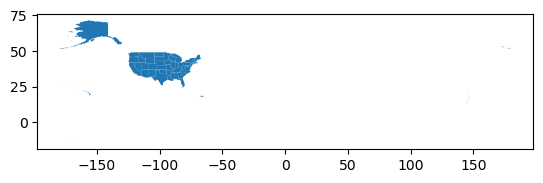

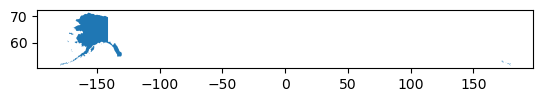

In [6]:
alaska = states[states['name'] == 'Alaska']
alaska.plot()

In [7]:
# reprokject to CRS optimized for AK
alaska = alaska.to_crs('epsg:3338')

# inspect the new CRS
alaska.crs

<Projected CRS: EPSG:3338>
Name: NAD83 / Alaska Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - Alaska.
- bounds: (172.42, 51.3, -129.99, 71.4)
Coordinate Operation:
- name: Alaska Albers (meter)
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

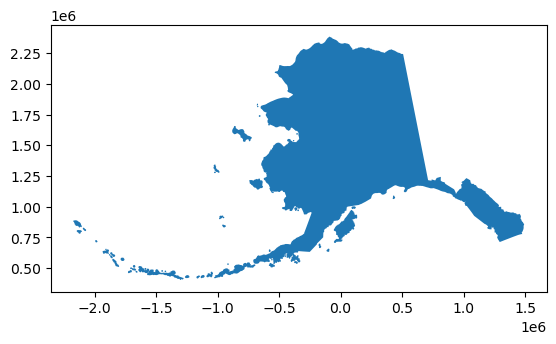

In [8]:
alaska.plot()

## Prepare populated places points

In [9]:
print('CRS: ', places.crs)
print(len(places))
places.head()

CRS:  EPSG:4326
1251


,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,capin,worldcity,megacity,sov0name,sov_a3,adm0name,adm0_a3,adm1name,iso_a2,note,latitude,longitude,pop_max,pop_min,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry
0,10,1,5,Admin-1 region capital,Bombo,None,None,Bombo,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Bamunanika,UG,None,0.583299,32.533300,75000,21000,0.0,8,7,None,None,7.0,1159113923,POINT (32.53330 0.58330)
1,10,1,5,Admin-1 region capital,Fort Portal,None,None,Fort Portal,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Kabarole,UG,None,0.671004,30.275002,42670,42670,0.0,7,7,None,None,7.0,1159113959,POINT (30.27500 0.67100)
2,10,1,3,Admin-1 region capital,Potenza,None,None,Potenza,0,0,None,0,0,Italy,ITA,Italy,ITA,Basilicata,IT,None,40.642002,15.798997,69060,69060,0.0,8,8,None,None,7.0,1159117259,POINT (15.79900 40.64200)
3,10,1,3,Admin-1 region capital,Campobasso,None,None,Campobasso,0,0,None,0,0,Italy,ITA,Italy,ITA,Molise,IT,None,41.562999,14.655997,50762,50762,0.0,8,8,None,None,7.0,1159117283,POINT (14.65600 41.56300)
4,10,1,3,Admin-1 region capital,Aosta,None,None,Aosta,0,0,None,0,0,Italy,ITA,Italy,ITA,Valle d'Aosta,IT,None,45.737001,7.315003,34062,34062,0.0,7,7,None,None,7.0,1159117361,POINT (7.31500 45.73700)


<Axes: >

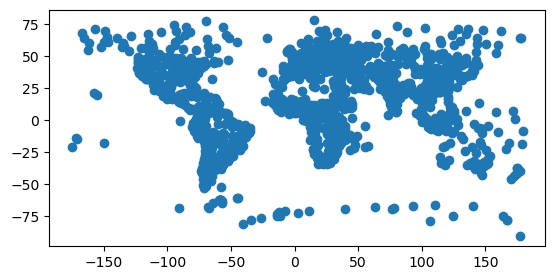

In [10]:
places.plot()

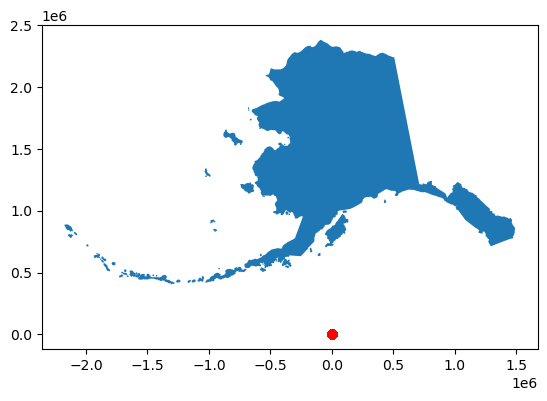

In [11]:
fig, ax = plt.subplots()
alaska.plot(ax=ax)
places.plot(ax=ax,
            color = 'red')
plt.show()


In [12]:
# reproject to match alaska CRS
places = places.to_crs(alaska.crs)
assert alaska.crs == places.crs

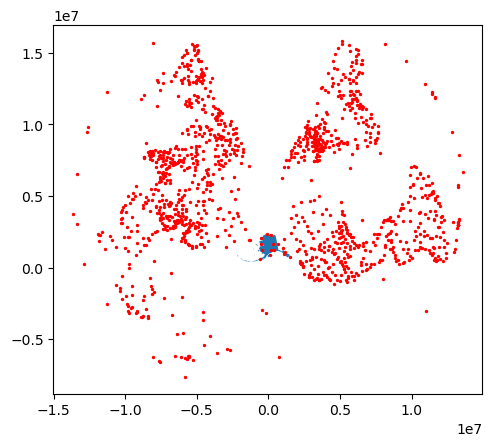

In [13]:
fig, ax = plt.subplots()
alaska.plot(ax=ax)
places.plot(ax=ax,
            color = 'red',
            markersize=2)
plt.show()

## Clipping
using a polygon(s) to keep only the parts of the geoetries that fall inside them.
The general syntax is:

```python
updated_geodf = geopandas.clip(geodf, mask)
```

where:
- `updated_geodf` = intersection of the geometries in `geodf` with `mask`
- `geodf` = the `geopandas.GeoDataframe` we want to clip
- `mask` = a 'gpd.GDF' with the polygons we will use for clipping

remember: a `mask` and geoDF must be in the same CRS

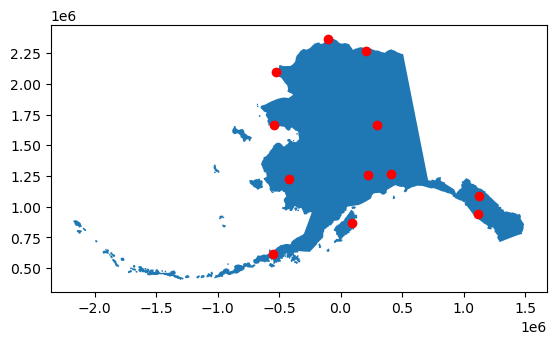

In [14]:
# clip populated places to AK multipolygon

ak_places = gpd.clip(places, alaska)

fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_places.plot(ax=ax,
               color = 'red')
plt.show()

## prepare roads dataset

In [15]:
print('CRS: ', roads.crs)
print(len(roads))
roads.head()

CRS:  EPSG:4326
56600


,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
0,8,Road,Secondary Highway,CAN,None,"Version 1.5: Changed alignment, a few adds in ...",None,None,None,None,0,3,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,314705,North America,0,None,7.1,9.6,"LINESTRING (-133.32533 62.21571, -133.31664 62..."
1,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",83,None,None,None,0,164,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,108105,North America,0,Federal,7.0,8.6,"LINESTRING (-100.50543 42.80753, -100.53495 42..."
2,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",840,None,None,None,0,98,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,U/C,7.0,9.5,"LINESTRING (-87.27432 36.02439, -87.22916 35.9..."
3,8,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",151,None,None,None,0,17,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,Federal,7.1,9.6,"LINESTRING (-87.72757 44.15165, -87.57301 44.1..."
4,6,Road,Major Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",GSP,None,None,None,0,33,1,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,311305,North America,1,State,6.0,8.5,"MULTILINESTRING ((-74.75920 39.14301, -74.6735..."


<Axes: >

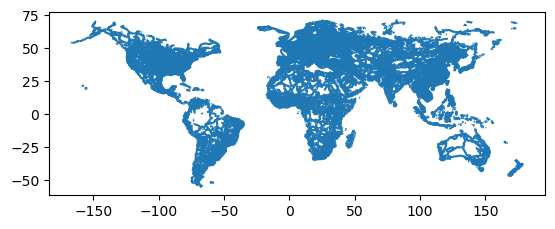

In [16]:
roads.plot()

In [17]:
# reproject to match alaska CRS
# roads = roads.to_crs(alaska.crs)
# assert alaska.crs == roads.crs

<Axes: >

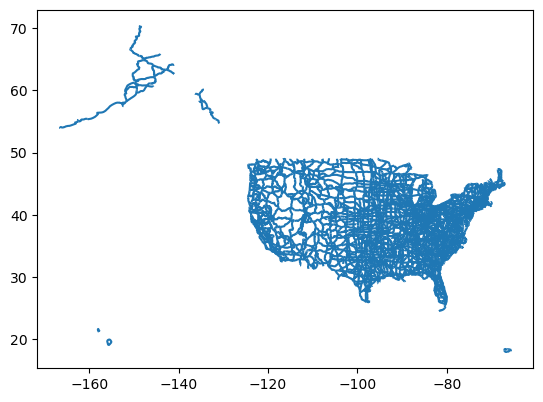

In [18]:
# clip roads to AK multipolygon

usa_roads = roads[roads['sov_a3'] == 'USA']
usa_roads.plot()

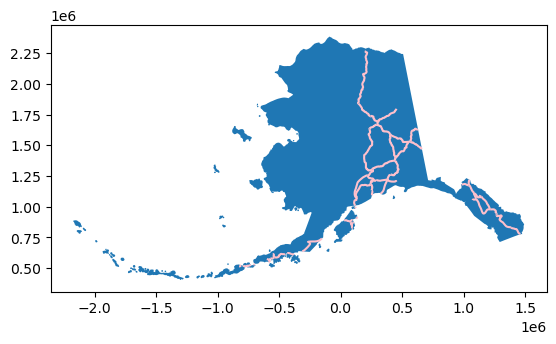

In [19]:
# clip usa roads to AK geometry

ak_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska)
fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_roads.plot(ax=ax,
              color='pink')
plt.show()

## Clip to a bounding box

In [20]:
# take a look at the values that define the bbox
alaska.total_bounds

array([-2175729.73162241,   404545.10791528,  1493082.30904445,
        2383808.43520815])

In [21]:
ak_complete_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska.total_bounds)

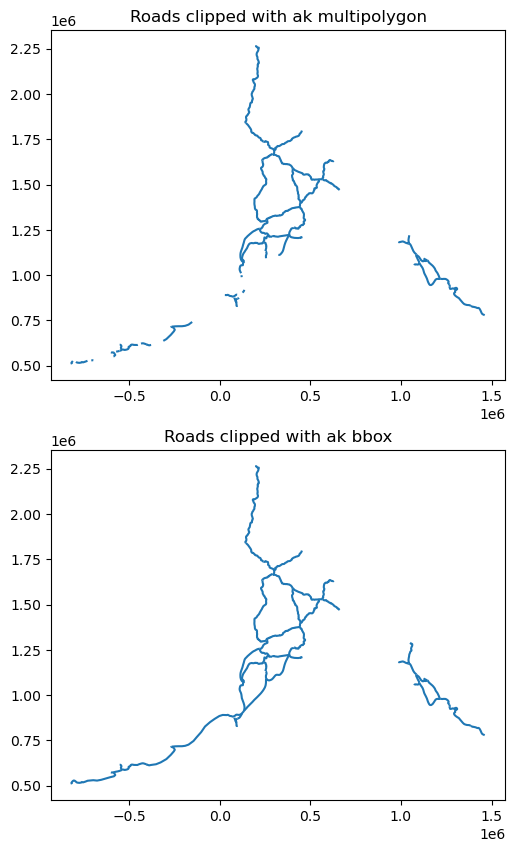

In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (10, 10))

ak_roads.plot(ax=ax1)
ax1.set_title('Roads clipped with ak multipolygon')

ak_complete_roads.plot(ax=ax2)
ax2.set_title('Roads clipped with ak bbox')

plt.show()

## measuring length

Geodataframes have a `length` attribute that clculates the length of each line in the geometry , in the units of the CRS

let's try it on one road in Alaska

In [23]:
# Reminder: this usa_roads is in EPSG: 4326 geographic CRS
usa_roads.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [24]:
usa_roads.loc[[1138]].length

/var/folders/56/b_9_yjts0v342_1hpg9ctd6c0000gn/T/ipykernel_99783/3731596667.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  usa_roads.loc[[1138]].length


1138    4.051932
dtype: float64

In [27]:
# Reproject to the alaska crs and measurement in km
usa_roads.loc[[1138]].to_crs('epsg:3388').length / 1000


1138    365.604507
dtype: float64

## how does clipping affect the data?

In [32]:
print('Number of roads (polygon clip:', len(ak_roads))
print('Number of roads (bbox clip:)', len(ak_complete_roads))

print('Total length in km (polygon clip): ', round(ak_roads.length.sum()/1000))
print('Total length in km (bbox clip): ', round(ak_complete_roads.length.sum()/1000))

Number of roads (polygon clip: 56
Number of roads (bbox clip:) 56
Total length in km (polygon clip):  6069
Total length in km (bbox clip):  7111


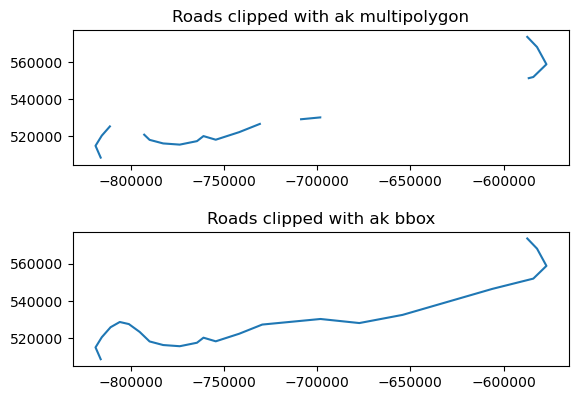

In [33]:
fig, (ax1, ax2) = plt.subplots(2, 1)

ak_roads.loc[[1138]].plot(ax=ax1)
ax1.set_title('Roads clipped with ak multipolygon')

ak_complete_roads.loc[[1138]].plot(ax=ax2)
ax2.set_title('Roads clipped with ak bbox')

plt.show()

In [35]:
print('Length of 1138 in km (polygon clip): ', round(ak_roads.loc[[1138]].length.sum()/1000))
print('Length of 1138 in km (bbox clip): ', round(ak_complete_roads.loc[[1138]].length.sum()/1000))

Length of 1138 in km (polygon clip):  132
Length of 1138 in km (bbox clip):  287


## Plot everything together

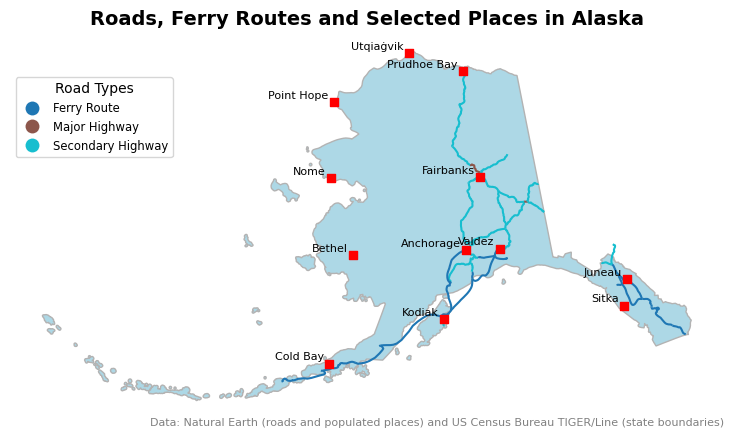

In [44]:
fig, ax = plt.subplots(figsize=(11,5))
ax.axis('off')

alaska.plot(ax=ax, color='lightblue', edgecolor='0.7')

ak_complete_roads.plot(ax=ax, 
                       zorder=1,  # Specify layer plotting order
                       column='type', 
                       legend=True,
                       legend_kwds={'title': "Road Types", 
                                    'loc': 'upper left',
                                    'bbox_to_anchor':(0,0.9),
                                    'fontsize':'small'}
                                    )

ak_places.plot(ax=ax, 
               zorder=2,  # Specify layer plotting order
               color='red', 
               marker='s'  # Square marker
               )
# Add city names as text annotations
for x, y, name in zip(ak_places.geometry.x, ak_places.geometry.y, ak_places['name']):
    ax.text(x-30000, y+20000, name, fontsize=8, ha='right')

ax.set_title("Roads, Ferry Routes and Selected Places in Alaska", fontsize=14, fontweight='bold')

# Add data sources below the map
ax.annotate("Data: Natural Earth (roads and populated places) and US Census Bureau TIGER/Line (state boundaries)",
            xy=(1, 0), xycoords='axes fraction',  # Bottom-right corner of the axes
            ha='right', va='top', fontsize=8, color='gray')

plt.show()